In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [3]:
df = pd.read_csv('spotify_hits_10s.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'spotify_hits_10s.csv'

In [ ]:
df.describe()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
count,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6.398000e+03,6398.000000,6398.000000,6398.000000,6398.000000
mean,0.568163,0.667756,5.283526,-7.589796,0.645514,0.098018,0.216928,0.165293,0.196700,0.443734,122.353871,2.367042e+05,3.930916,41.028399,10.316505,0.500000
std,0.191103,0.240721,3.606216,5.234592,0.478395,0.097224,0.296835,0.318736,0.166148,0.245776,29.847389,8.563698e+04,0.377469,19.568827,3.776011,0.500039
min,0.062200,0.000251,0.000000,-46.655000,0.000000,0.022500,0.000000,0.000000,0.016700,0.000000,39.369000,2.985300e+04,0.000000,0.000000,2.000000,0.000000
25%,0.447000,0.533000,2.000000,-8.425000,0.000000,0.038825,0.008533,0.000000,0.096800,0.240000,98.091250,1.932068e+05,4.000000,28.059135,8.000000,0.000000
50%,0.588000,0.712500,5.000000,-6.096500,1.000000,0.057200,0.067050,0.000017,0.126000,0.434000,121.070000,2.212465e+05,4.000000,36.265365,10.000000,0.500000
75%,0.710000,0.857000,8.000000,-4.601250,1.000000,0.112000,0.311000,0.057650,0.249000,0.628000,141.085000,2.593165e+05,4.000000,48.292538,12.000000,1.000000
max,0.981000,0.999000,11.000000,-0.149000,1.000000,0.956000,0.996000,0.995000,0.982000,0.976000,210.977000,1.734201e+06,5.000000,213.154990,88.000000,1.000000


In [ ]:
df = df.drop(['track', 'artist', 'uri'], axis=1)
df.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


In [ ]:
df.isnull().sum()


,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6398 entries, 0 to 6397
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      6398 non-null   float64
 1   energy            6398 non-null   float64
 2   key               6398 non-null   int64  
 3   loudness          6398 non-null   float64
 4   mode              6398 non-null   int64  
 5   speechiness       6398 non-null   float64
 6   acousticness      6398 non-null   float64
 7   instrumentalness  6398 non-null   float64
 8   liveness          6398 non-null   float64
 9   valence           6398 non-null   float64
 10  tempo             6398 non-null   float64
 11  duration_ms       6398 non-null   int64  
 12  time_signature    6398 non-null   int64  
 13  chorus_hit        6398 non-null   float64
 14  sections          6398 non-null   int64  
 15  target            6398 non-null   int64  
dtypes: float64(10), int64(6)
memory usage: 799

/tmp/ipykernel_827/387383525.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


Text(0, 0.5, 'Count')

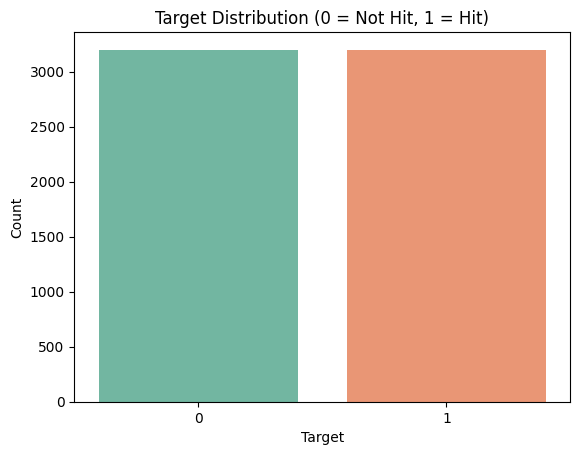

In [ ]:
plt.figure()
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Target Distribution (0 = Not Hit, 1 = Hit)')
plt.xlabel('Target')
plt.ylabel('Count')


Text(0.5, 1.0, 'Correlation Heatmap')

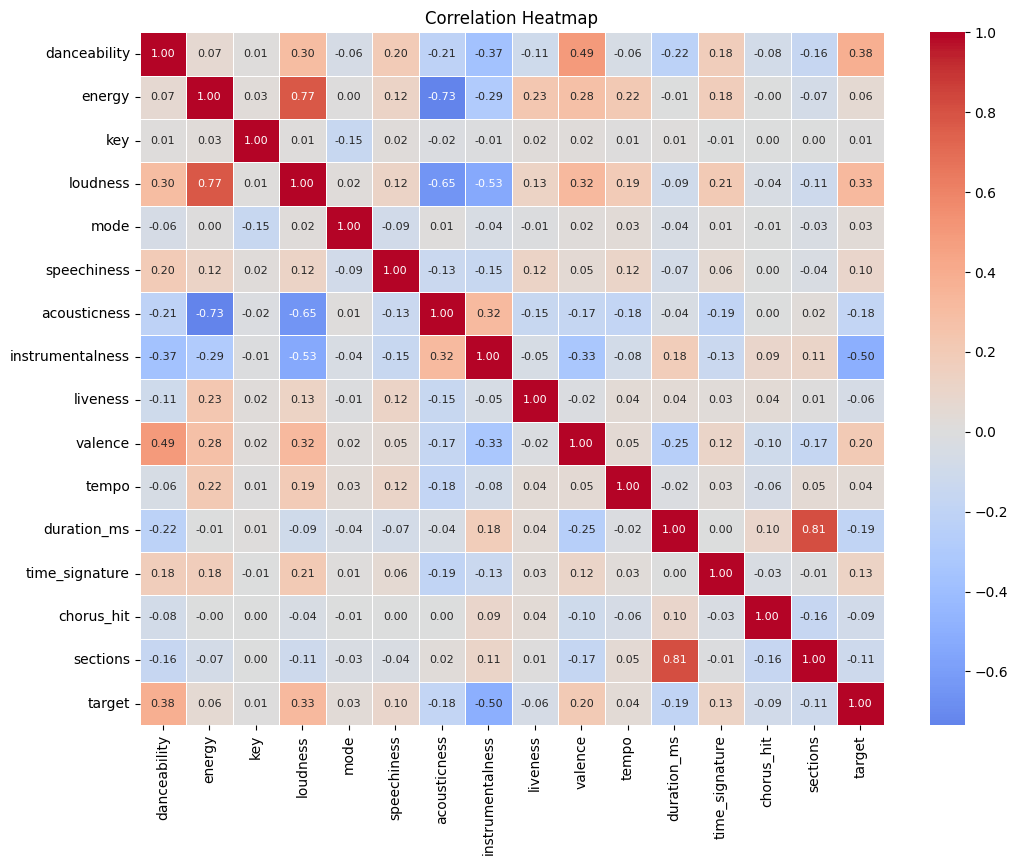

In [ ]:
plt.figure(figsize=(12, 9))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={"size": 8})
plt.title('Correlation Heatmap')

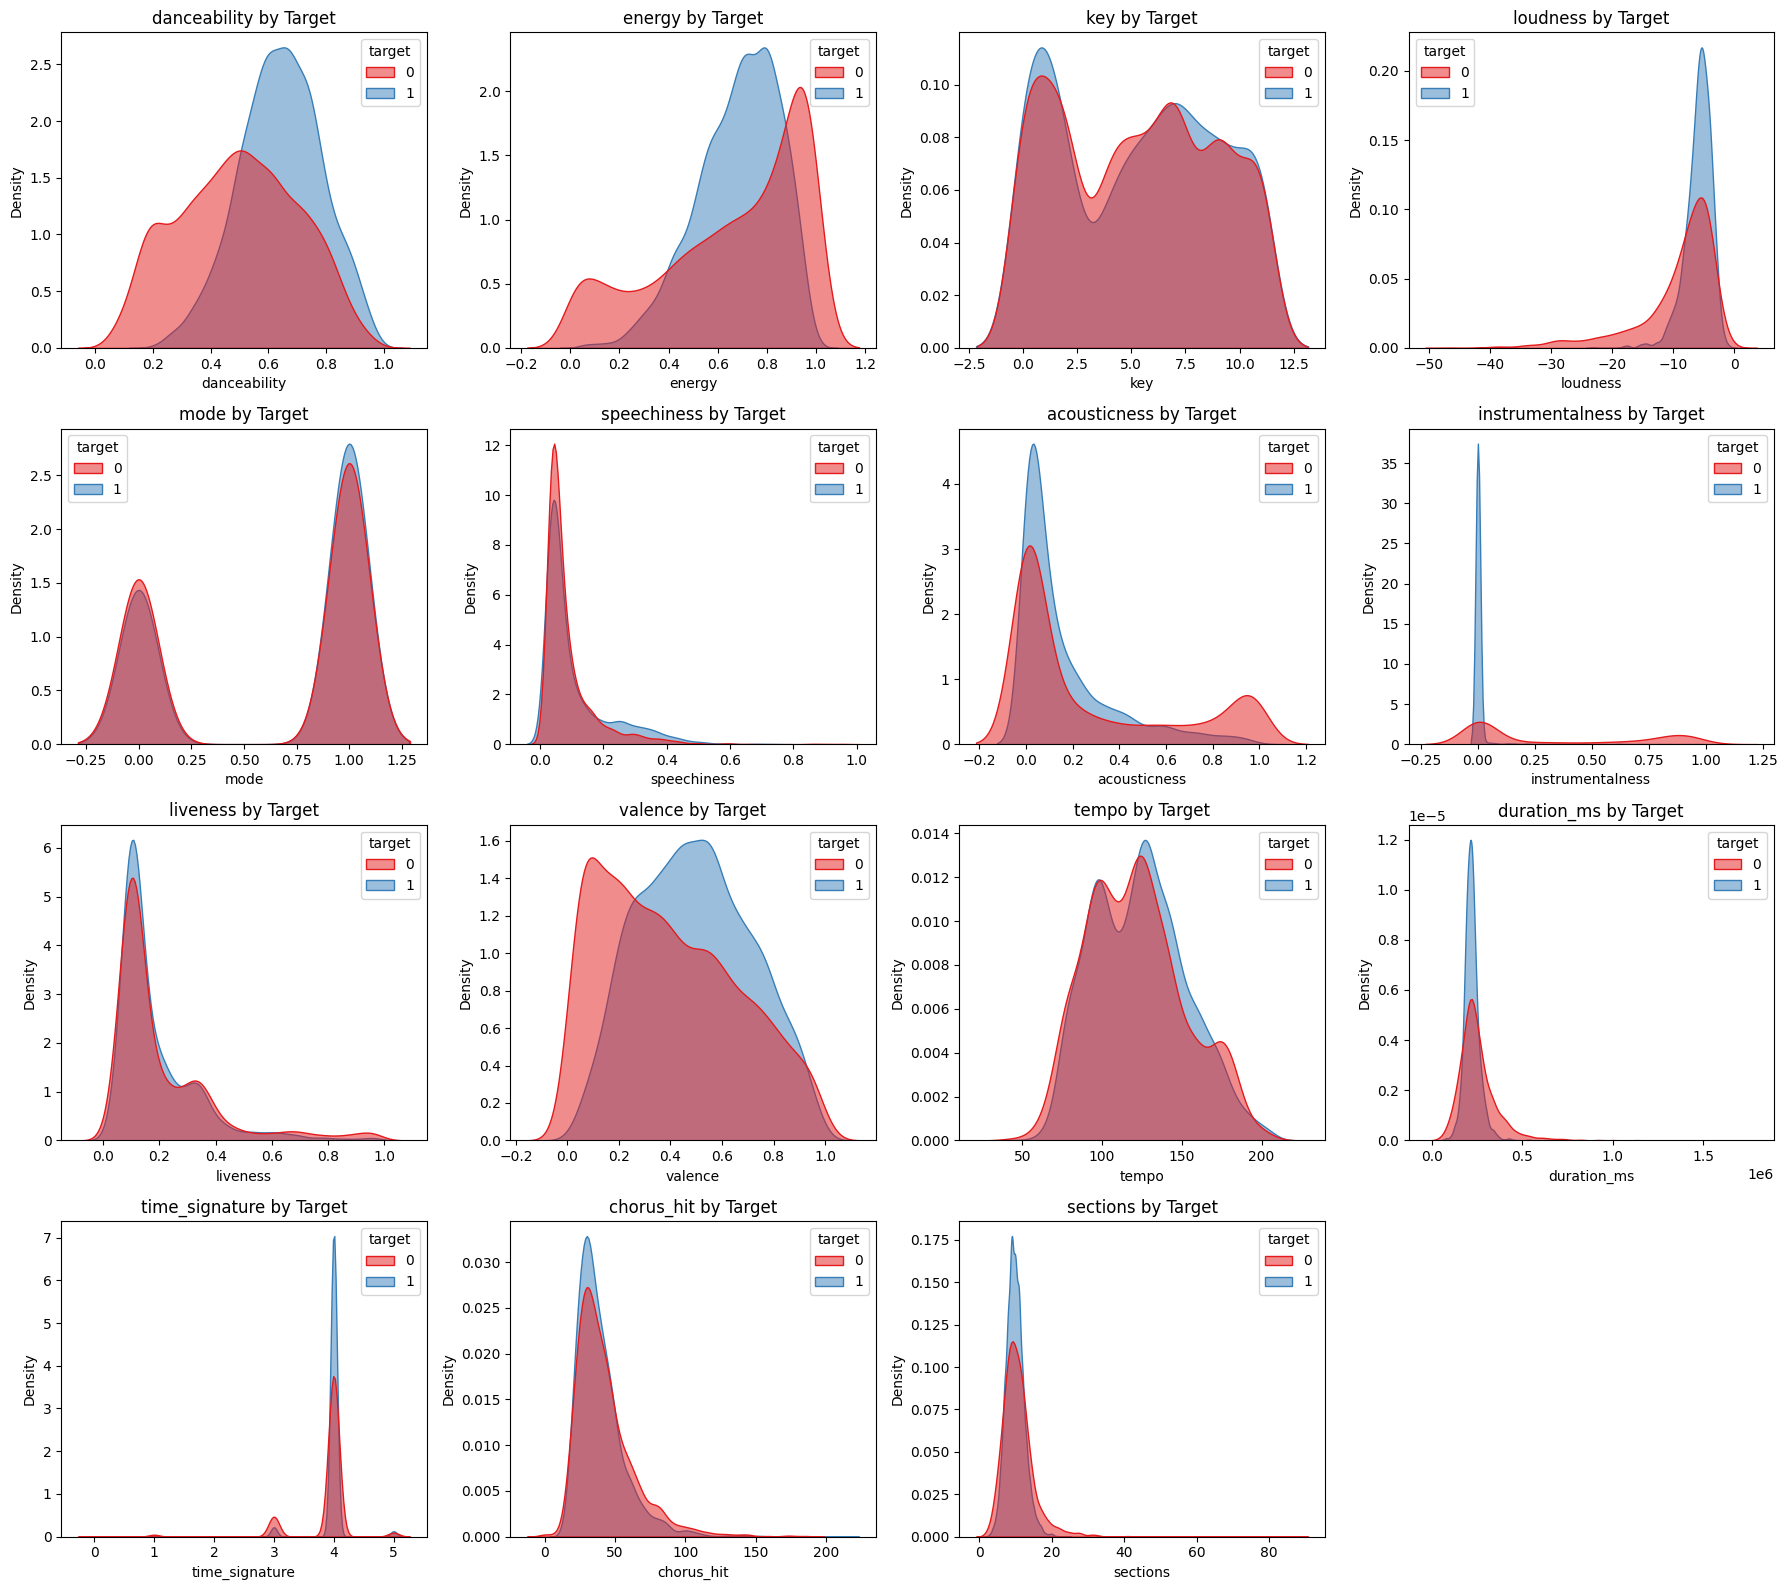

In [ ]:
features_dist = df.columns.drop(['target'])
n = len(features_dist)
cols = 4
rows = -(-n // cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 4*rows))
axes = axes.flatten()

for ax, feat in zip(axes, features_dist):
    sns.kdeplot(data=df, x=feat, hue='target', fill=True,
                common_norm=False, alpha=0.5, ax=ax, palette='Set1')
    ax.set_title(f'{feat} by Target')

for ax in axes[len(features_dist):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

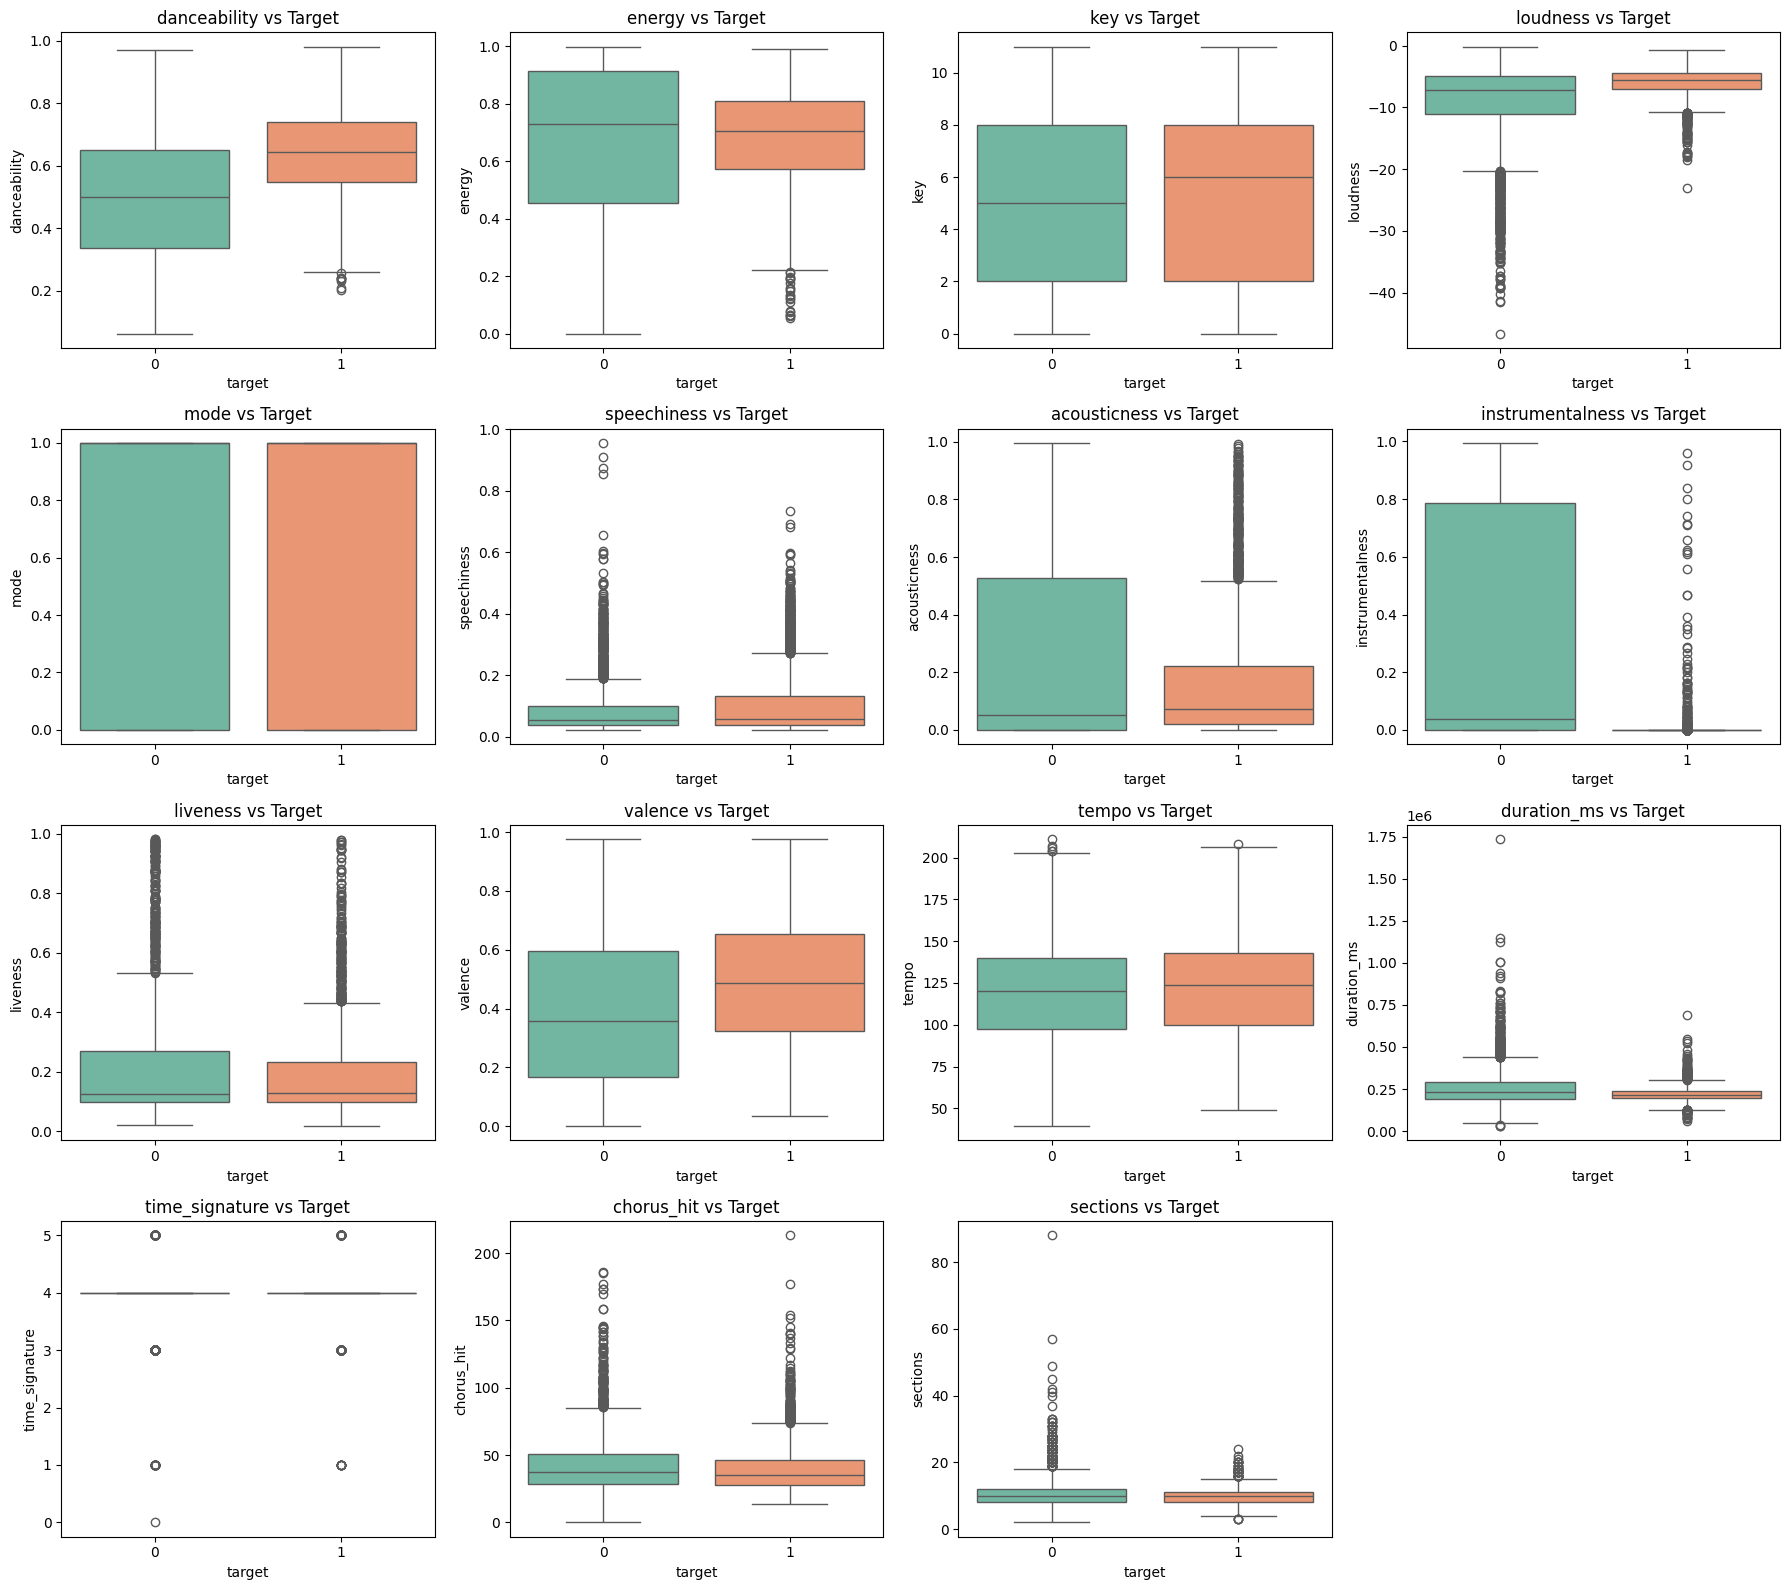

In [ ]:
features_box = df.columns.drop(['target'])
n = len(features_box)
cols = 4
rows = -(-n // cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 4 * rows))
axes = axes.flatten()

for ax, feat in zip(axes, features_box):
    sns.boxplot(x='target', y=feat, hue='target', data=df, palette='Set2', ax=ax, legend=False)
    ax.set_title(f'{feat} vs Target')

for ax in axes[len(features_box):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Energy vs Danceability (colored by Target)')

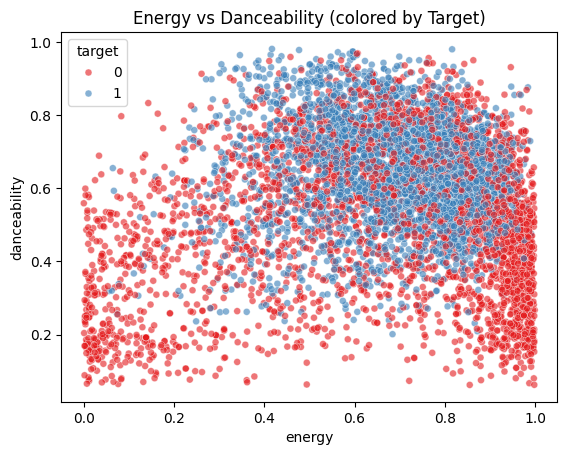

In [ ]:
plt.figure()
sns.scatterplot(x='energy', y='danceability', hue='target', data=df,
                 palette='Set1', alpha=0.6, s=25)
plt.title('Energy vs Danceability (colored by Target)')

Text(0.5, 1.02, 'Pairplot of Top Features')

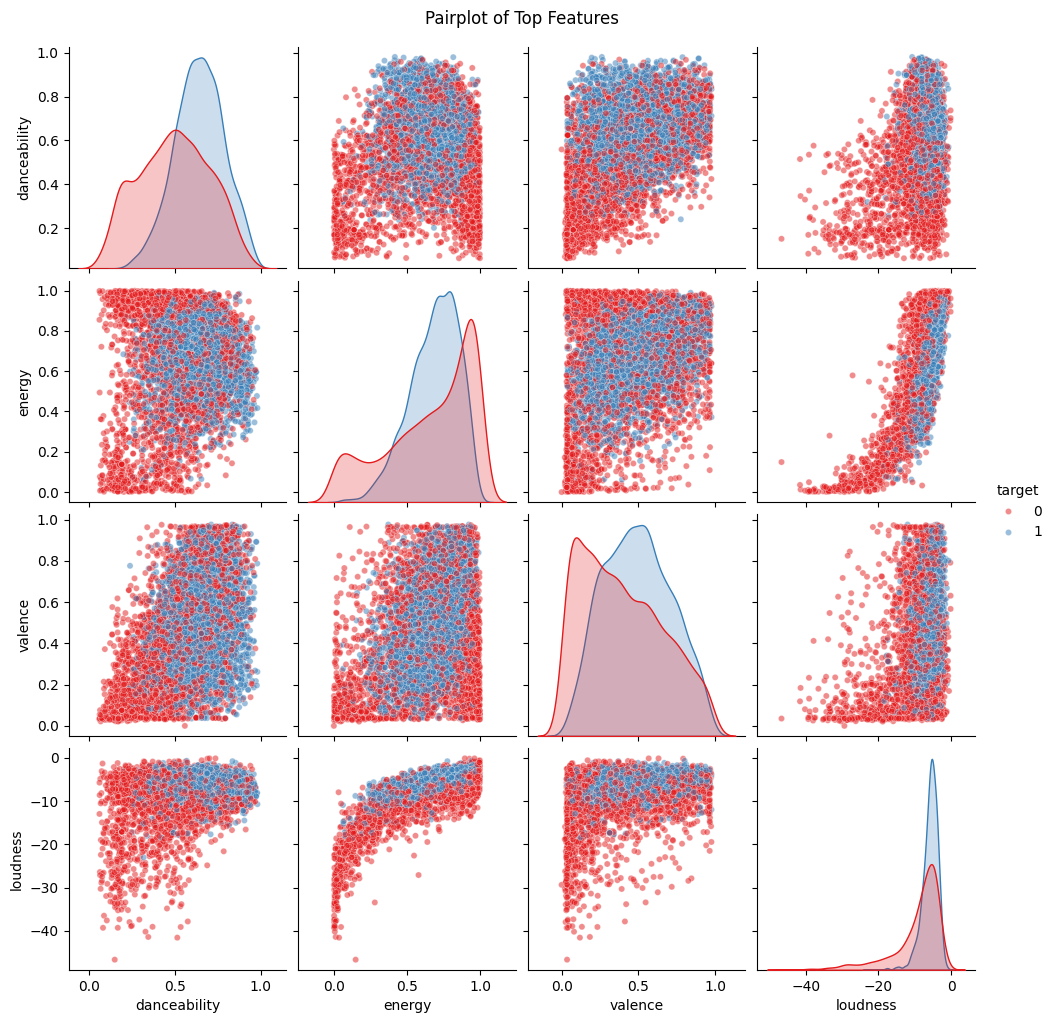

In [ ]:
top_features = ['danceability', 'energy', 'valence', 'loudness', 'target']
pairplot_fig = sns.pairplot(df[top_features], hue='target', palette='Set1',
                             plot_kws={'alpha': 0.5, 's': 20}, diag_kind='kde')
pairplot_fig.fig.suptitle('Pairplot of Top Features', y=1.02)

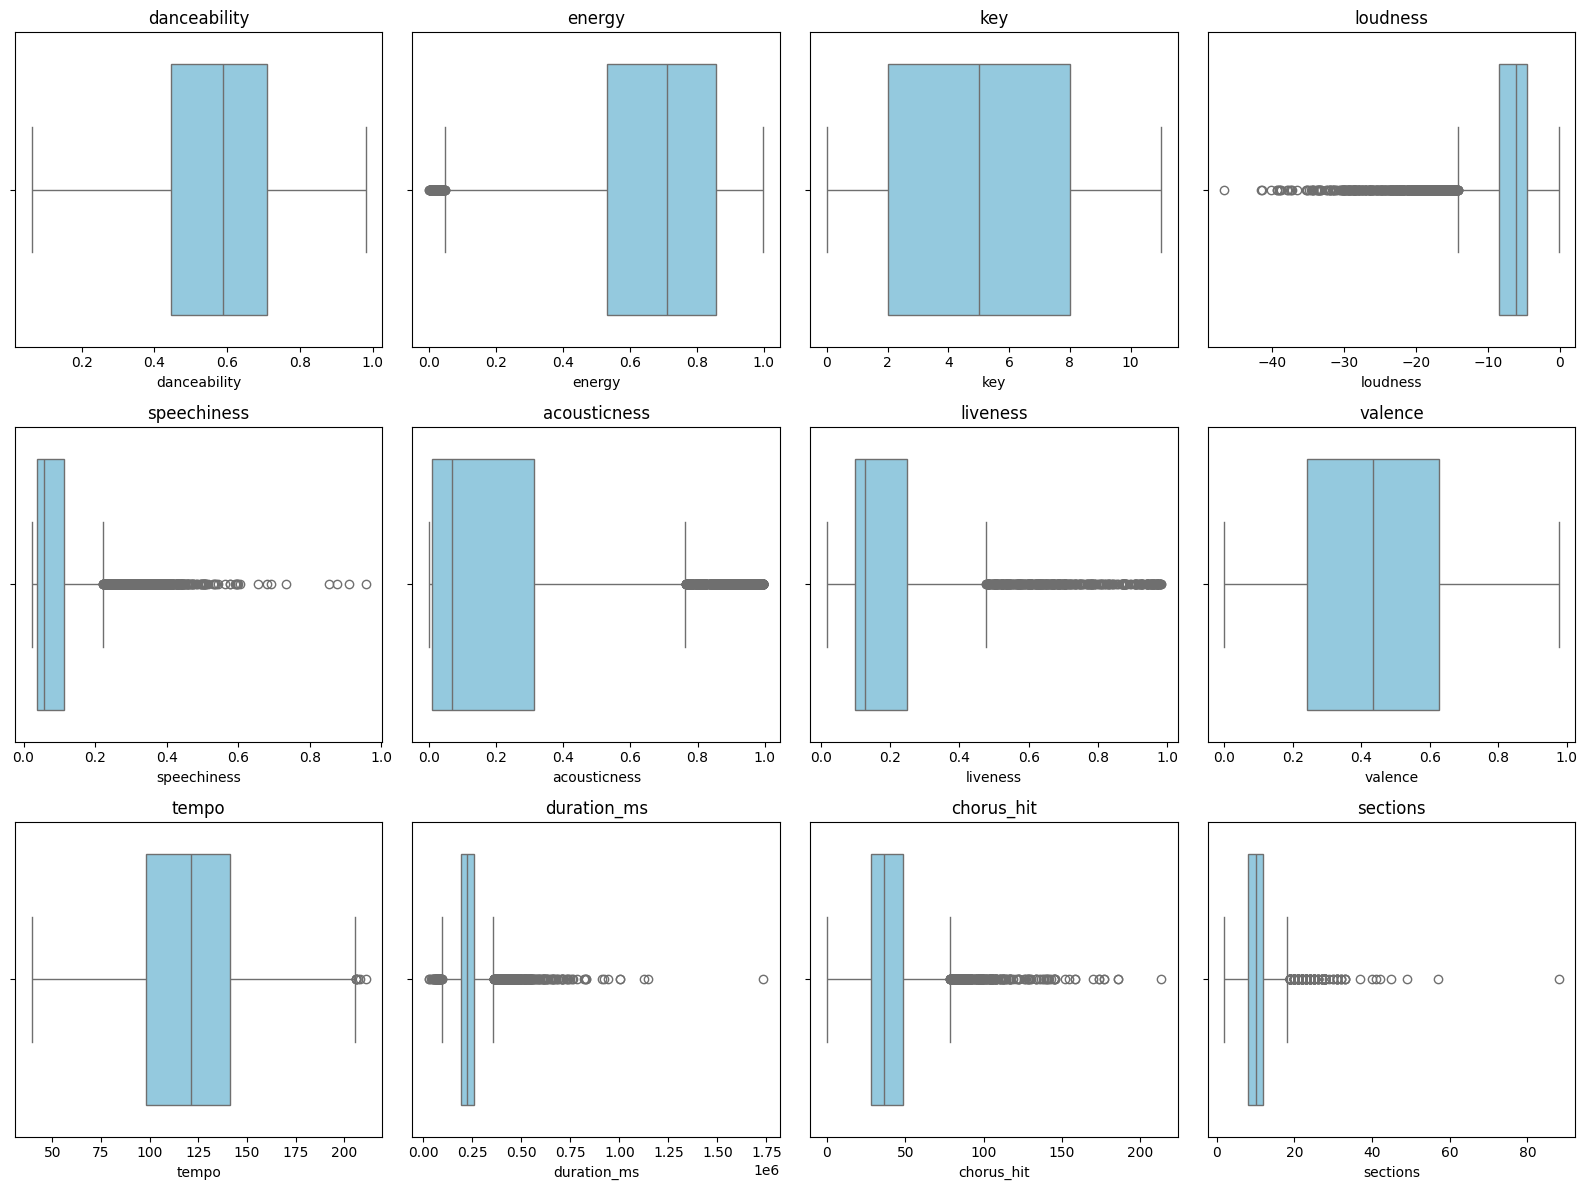

In [ ]:
cols_to_check = df.columns.drop(['target', 'mode', 'time_signature', 'instrumentalness'])

fig, ax_grid = plt.subplots(3, 4, figsize=(16, 12))
for ax, col in zip(ax_grid.flatten(), cols_to_check):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
skewed_cols = ['speechiness', 'acousticness', 'liveness']
for col in skewed_cols:
    df[col] = np.log1p(df[col])

In [ ]:
def cap_outliers(df, col, factor=1.5):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    df[col] = df[col].clip(lower, upper)
    return df, lower, upper

outlier_cols = ['duration_ms', 'chorus_hit', 'sections', 'tempo', 'loudness']

saved_outlier_bounds = {}

for col in outlier_cols:
    df, lower, upper = cap_outliers(df, col)
    saved_outlier_bounds[col] = (lower, upper)



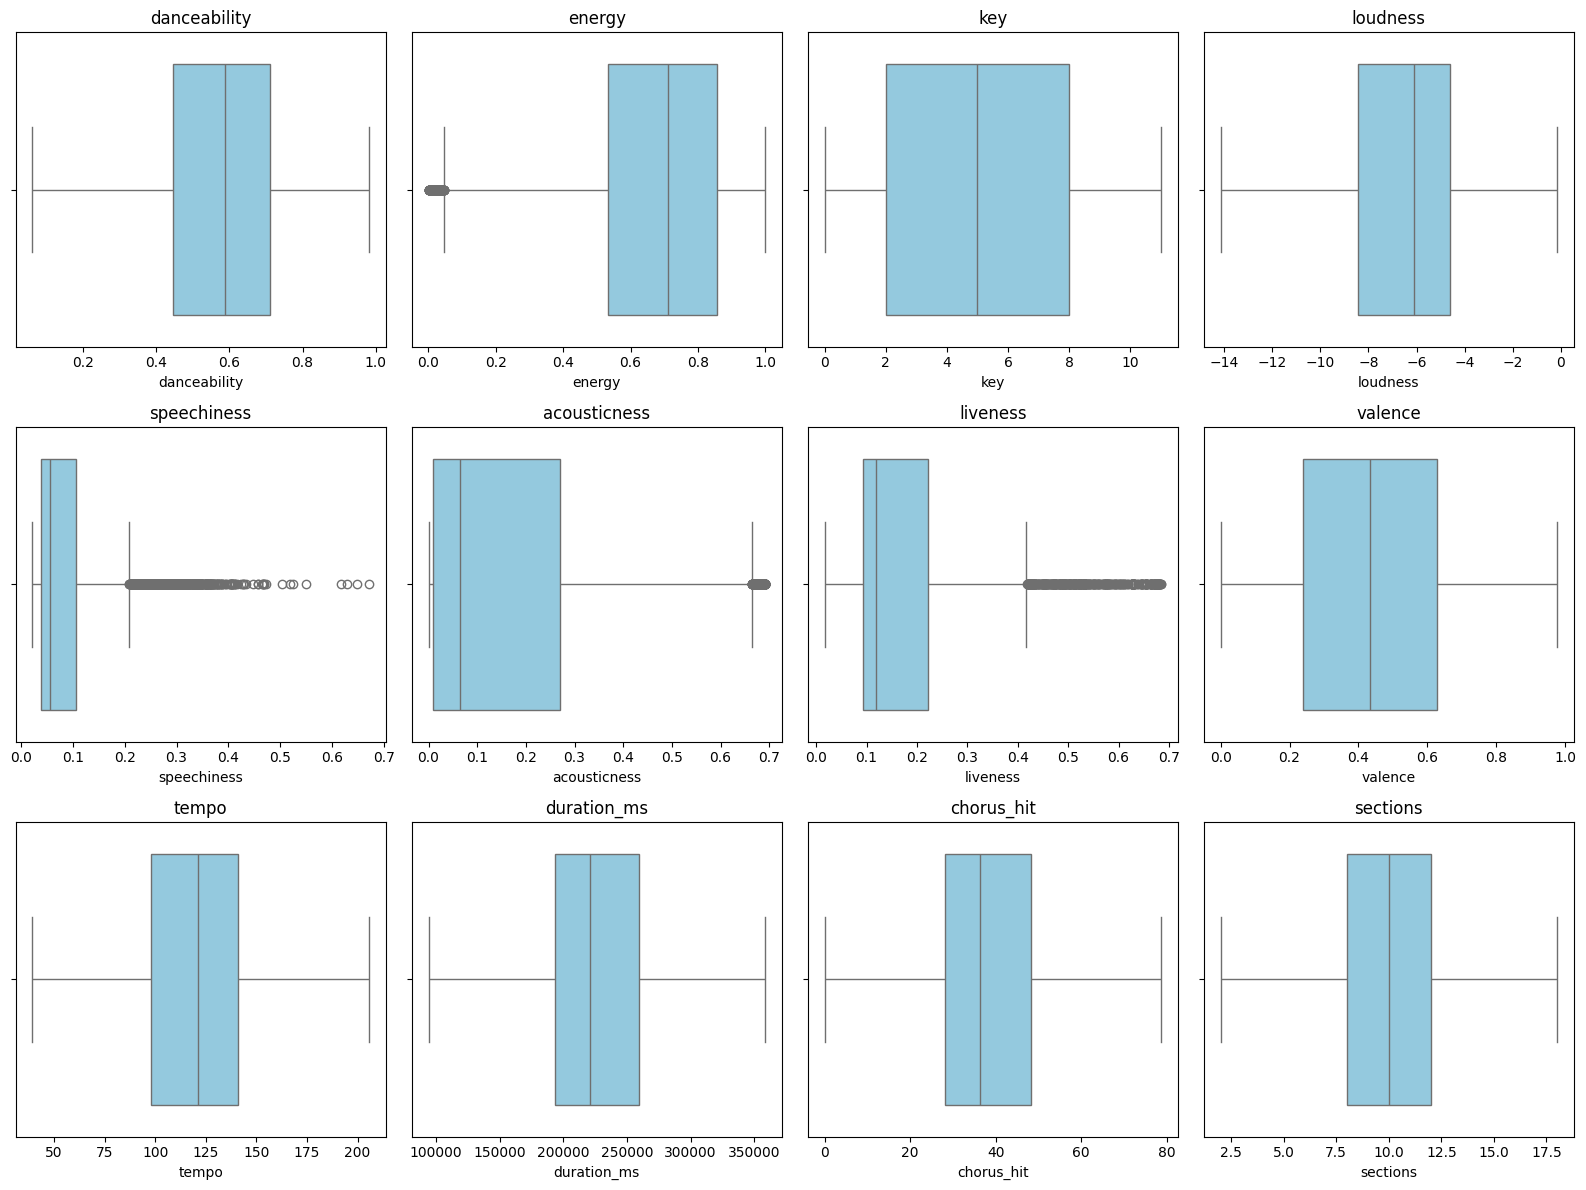

In [ ]:
fig, ax_grid = plt.subplots(3, 4, figsize=(16, 12))
for ax, col in zip(ax_grid.flatten(), cols_to_check):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
scaler = MinMaxScaler()

cols_to_scale = ['loudness', 'tempo', 'duration_ms', 'key', 'time_signature','chorus_hit', 'sections']

df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

In [ ]:
df.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,0.741,0.626,0.090909,0.666206,0,0.084892,0.019803,0.000,0.079550,0.706,0.413100,0.357175,0.8,0.523721,0.5000,1
1,0.447,0.247,0.454545,0.000000,0,0.034015,0.626473,0.814,0.090389,0.250,0.698648,0.313259,0.6,0.421919,0.4375,0
2,0.550,0.415,0.818182,0.542665,0,0.050693,0.149282,0.000,0.102557,0.274,0.798380,0.421348,0.8,0.570829,0.4375,1
3,0.502,0.648,0.000000,0.603972,0,0.051358,0.005117,0.000,0.185649,0.291,0.315679,0.374381,0.8,0.375435,0.3125,0
4,0.807,0.887,0.090909,0.732865,1,0.242946,0.003803,0.000,0.330023,0.780,0.728900,0.189843,0.8,0.317792,0.3750,1


In [ ]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)


In [ ]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train shape:", y_train.shape)
print("Test shape:", y_test.shape)

Train shape: (5758, 15)
Test shape: (640, 15)
Train shape: (5758,)
Test shape: (640,)


## ML Models for comparison

In [ ]:
results = []
#Decision Tree
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_preds = dt.predict(X_test)

results.append({
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, dt_preds),
        "Precision": precision_score(y_test, dt_preds),
        "Recall": recall_score(y_test, dt_preds),
        "F1": f1_score(y_test, dt_preds),
    })

print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, dt_preds))
print("Precision:", precision_score(y_test, dt_preds))
print("Recall:", recall_score(y_test, dt_preds))
print("F1:", f1_score(y_test, dt_preds))
print()

Decision Tree
Accuracy: 0.8140625
Precision: 0.7762039660056658
Recall: 0.8726114649681529
F1: 0.8215892053973014



In [ ]:
#Random Forest
rf = RandomForestClassifier(n_estimators=350, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

results.append({
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_preds),
        "Precision": precision_score(y_test, rf_preds),
        "Recall": recall_score(y_test, rf_preds),
        "F1": f1_score(y_test, rf_preds),
    })

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(y_test, rf_preds))
print("Recall:", recall_score(y_test, rf_preds))
print("F1:", f1_score(y_test, rf_preds))
print()

Random Forest
Accuracy: 0.8609375
Precision: 0.8299120234604106
Recall: 0.9012738853503185
F1: 0.8641221374045801



In [ ]:
# Support Vector Machine
svm = SVC(C= 3.5,kernel='rbf', random_state=42)
svm.fit(X_train, y_train)
svm_preds = svm.predict(X_test)

results.append({
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, svm_preds),
        "Precision": precision_score(y_test, svm_preds),
        "Recall": recall_score(y_test, svm_preds),
        "F1": f1_score(y_test, svm_preds),
    })

print("SVM")
print("Accuracy:", accuracy_score(y_test, svm_preds))
print("Precision:", precision_score(y_test, svm_preds))
print("Recall:", recall_score(y_test, svm_preds))
print("F1:", f1_score(y_test, svm_preds))

SVM
Accuracy: 0.8375
Precision: 0.7792553191489362
Recall: 0.9331210191082803
F1: 0.8492753623188406


In [ ]:
#XGBoost
xgb = XGBClassifier(n_estimators=350, random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)

results.append({
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_preds),
        "Precision": precision_score(y_test, xgb_preds),
        "Recall": recall_score(y_test, xgb_preds),
        "F1": f1_score(y_test, xgb_preds),
    })

print("XGBoost")
print("Accuracy:", accuracy_score(y_test, xgb_preds))
print("Precision:", precision_score(y_test, xgb_preds))
print("Recall:", recall_score(y_test, xgb_preds))
print("F1:", f1_score(y_test, xgb_preds))
print()

XGBoost
Accuracy: 0.84375
Precision: 0.811046511627907
Recall: 0.8885350318471338
F1: 0.8480243161094225



In [ ]:
#Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=350,
    max_samples=0.6,
    random_state=42,
    n_jobs=-1,
)
bagging.fit(X_train, y_train)
bagging_preds = bagging.predict(X_test)

results.append({
        "Model": " Bagging",
        "Accuracy": accuracy_score(y_test, bagging_preds),
        "Precision": precision_score(y_test, bagging_preds),
        "Recall": recall_score(y_test, bagging_preds),
        "F1": f1_score(y_test, bagging_preds),
    })

print("Bagging")
print("Accuracy:", accuracy_score(y_test, bagging_preds))
print("Precision:", precision_score(y_test, bagging_preds))
print("Recall:", recall_score(y_test, bagging_preds))
print("F1:", f1_score(y_test, bagging_preds))
print()

Bagging
Accuracy: 0.85
Precision: 0.8263473053892215
Recall: 0.8789808917197452
F1: 0.8518518518518519



        Model  Accuracy  Precision   Recall       F1
Random Forest  0.860938   0.829912 0.901274 0.864122
      Bagging  0.850000   0.826347 0.878981 0.851852
      XGBoost  0.843750   0.811047 0.888535 0.848024
          SVM  0.837500   0.779255 0.933121 0.849275
Decision Tree  0.814063   0.776204 0.872611 0.821589


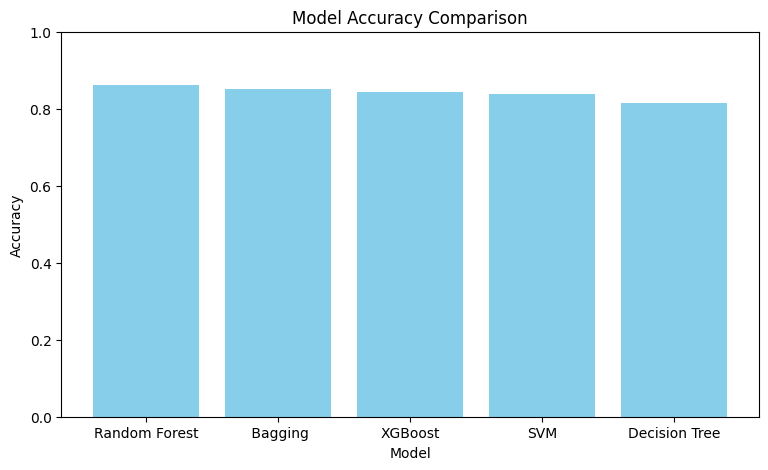

In [ ]:
# Define models Comparison

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print(results_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Accuracy"], color="skyblue")
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

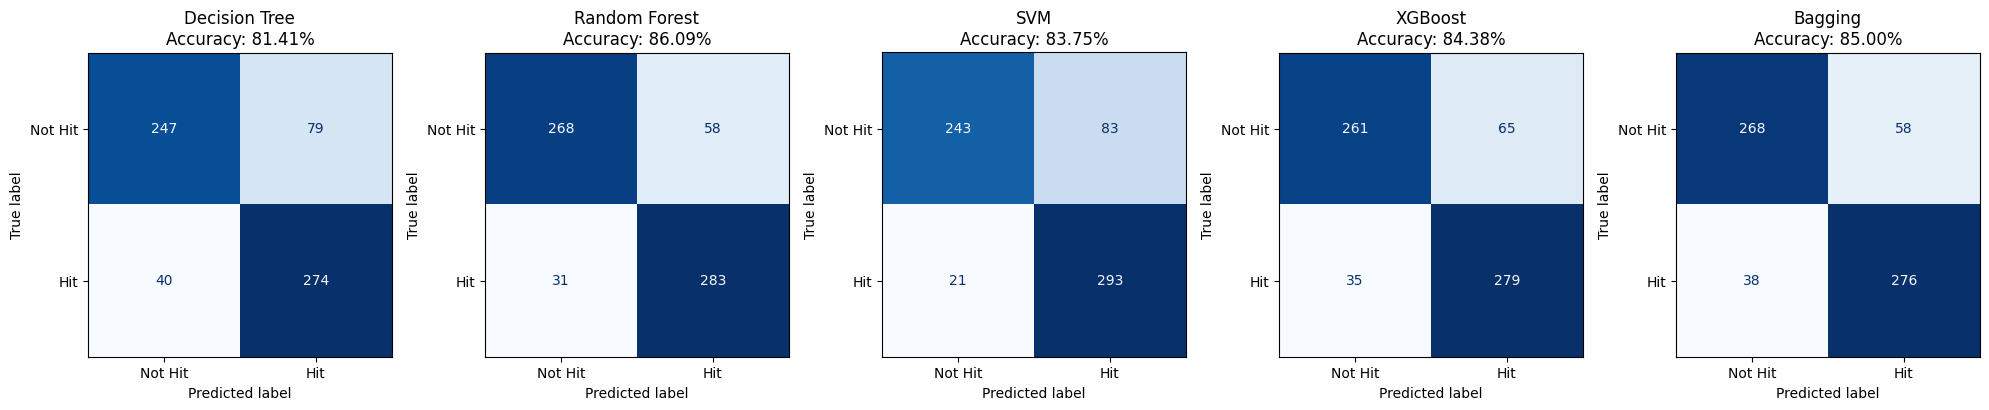

In [ ]:
#Confusion_Matrix
models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "SVM": svm,
    "XGBoost": xgb,
    "Bagging": bagging
}

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Hit', 'Hit'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\nAccuracy: {acc:.2%}')

plt.tight_layout()
plt.show()

In [ ]:
# Install Gradio
!pip install gradio -q

In [ ]:
# Import library
import gradio as gr

In [ ]:






# 1. PREPARE THE PREPROCESSING INFORMATION

# Features used by the ML models
feature_cols = X.columns.tolist()

# Features that were log-transformed during training (matches training exactly)
skewed_cols = ["speechiness", "acousticness", "liveness"]


# 2. CALCULATE OUTLIER BOUNDS
outlier_bounds = saved_outlier_bounds



# 3. PREPROCESS NEW USER INPUT
def preprocess_input(user_values):
    user_values = dict(user_values)


    # Convert dictionary to DataFrame
    row = pd.DataFrame([user_values])

    # Make sure the columns are in exactly the same order as the training data
    row = row[feature_cols]

    # Log transformation (must match training)
    for col in skewed_cols:
        row[col] = np.log1p(row[col])

    # Outlier capping
    for col in outlier_cols:
        lower, upper = outlier_bounds[col]
        row[col] = row[col].clip(lower=lower, upper=upper)

    # Scaling
    row[cols_to_scale] = scaler.transform(row[cols_to_scale])

    return row



# 4. PREDICTION FUNCTION
def predict_hit(
    danceability,
    energy,
    key,
    loudness,
    mode,
    speechiness,
    acousticness,
    instrumentalness,
    liveness,
    valence,
    tempo,
    duration_ms,
    time_signature,
    chorus_hit,
    sections
):

    # Collect the values entered by the user
    user_values = {

        "danceability": danceability,

        "energy": energy,

        "key": key,

        "loudness": loudness,

        "mode": mode,

        "speechiness": speechiness,

        "acousticness": acousticness,

        "instrumentalness": instrumentalness,

        "liveness": liveness,

        "valence": valence,

        "tempo": tempo,

        "duration_ms": duration_ms,

        "time_signature": time_signature,

        "chorus_hit": chorus_hit,

        "sections": sections
    }


    # Preprocess the new song
    X_new = preprocess_input(user_values)

    # Select the model
    model = models["Random Forest"]


    # Make prediction
    prediction = model.predict(X_new)[0]


    # Convert prediction into text
    if prediction == 1:

        prediction_text = "🎵 HIT"

    else:

        prediction_text = "❌ NOT A HIT"


    # Calculate confidence
    if hasattr(model, "predict_proba"):

        probabilities = model.predict_proba(X_new)[0]

        confidence = probabilities[int(prediction)]

        result = (
            f"{prediction_text}\n\n"
            f"Confidence: {confidence:.1%}"
        )

    else:

        result = (
            f"{prediction_text}\n\n"
        )


    return result





# 5. CREATE THE GUI
demo = gr.Interface(

    fn=predict_hit,

    inputs=[



        # MUSICAL FEATURES

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.6,
            step=0.01,
            label="🎵 Danceability"
        ),

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.6,
            step=0.01,
            label="⚡ Energy"
        ),

        gr.Slider(
            minimum=0,
            maximum=11,
            value=5,
            step=1,
            label="🎹 Key"
        ),

        gr.Slider(
            minimum=-60,
            maximum=0,
            value=-6,
            step=0.1,
            label="🔊 Loudness (dB)"
        ),

        gr.Radio(
            choices=[0, 1],
            value=1,
            label="🎼 Mode (0 = Minor, 1 = Major)"
        ),


        # AUDIO FEATURES

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.05,
            step=0.01,
            label="🗣 Speechiness"
        ),

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.2,
            step=0.01,
            label="🎸 Acousticness"
        ),

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0,
            step=0.01,
            label="🎻 Instrumentalness"
        ),

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.15,
            step=0.01,
            label="🎤 Liveness"
        ),

        gr.Slider(
            minimum=0,
            maximum=1,
            value=0.5,
            step=0.01,
            label="😊 Valence"
        ),

        gr.Slider(
            minimum=50,
            maximum=220,
            value=120,
            step=1,
            label="🥁 Tempo (BPM)"
        ),

        # SONG STRUCTURE

        gr.Number(
            value=210000,
            label="⏱ Duration (milliseconds)"
        ),

        gr.Slider(
            minimum=1,
            maximum=5,
            value=4,
            step=1,
            label="🎼 Time Signature"
        ),

        gr.Number(
            value=30000,
            label="🎵 Chorus Hit (milliseconds)"
        ),

        gr.Slider(
            minimum=1,
            maximum=20,
            value=10,
            step=1,
            label="📊 Sections"
        )
    ],


    # OUTPUT
    outputs=gr.Textbox(
        label="🎯 Prediction",
        lines=4
    ),


    # TITLE
    title="🎧 Spotify Hit Song Predictor",


    description=(
        "Enter the audio features of a song and "
        "predict whether it is likely to become a HIT."
    )
)


demo.launch(
    share=True,
    debug=True
)



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://299fd700a0d29f5892.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
